In [ ]:
pip install yellowbrick

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

In [ ]:
#input data
data = pd.read_csv("C:/Users/AirQualityUCI.csv")
data

,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,10/03/2004,18.00.00,2.6,1360,150,11.9,1046,166,1056,113,1692,1268,13.6,48.9,0.7578
1,10/03/2004,19.00.00,2.0,1292,112,9.4,955,103,1174,92,1559,972,13.3,47.7,0.7255
2,10/03/2004,20.00.00,2.2,1402,88,9.0,939,131,1140,114,1555,1074,11.9,54.0,0.7502
3,10/03/2004,21.00.00,2.2,1376,80,9.2,948,172,1092,122,1584,1203,11.0,60.0,0.7867
4,10/03/2004,22.00.00,1.6,1272,51,6.5,836,131,1205,116,1490,1110,11.2,59.6,0.7888
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9352,04/04/2005,10.00.00,3.1,1314,-200,13.5,1101,472,539,190,1374,1729,21.9,29.3,0.7568
9353,04/04/2005,11.00.00,2.4,1163,-200,11.4,1027,353,604,179,1264,1269,24.3,23.7,0.7119
9354,04/04/2005,12.00.00,2.4,1142,-200,12.4,1063,293,603,175,1241,1092,26.9,18.3,0.6406
9355,04/04/2005,13.00.00,2.1,1003,-200,9.5,961,235,702,156,1041,770,28.3,13.5,0.5139


In [ ]:
#missing value
data.replace(to_replace=-200, value=np.nan, inplace=True)

In [ ]:
data.isnull().sum()

Date                0
Time                0
CO(GT)           1683
PT08.S1(CO)       366
NMHC(GT)         8443
C6H6(GT)          366
PT08.S2(NMHC)     366
NOx(GT)          1639
PT08.S3(NOx)      366
NO2(GT)          1642
PT08.S4(NO2)      366
PT08.S5(O3)       366
T                 366
RH                366
AH                366
dtype: int64

In [ ]:
data.columns

Index(['Date', 'Time', 'CO(GT)', 'PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)',
       'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)',
       'PT08.S5(O3)', 'T', 'RH', 'AH'],
      dtype='object')

### Berdasarkan Permen KLHK nomor 14 tahun 2020, ISPU (Indeks Standard Pencemaran Udara) sebagaimana yang dimaksud pada ayat (1) meliputi parameter - parameter sebagai berikut:
* Partikulat (PM10)
* Partikulat (PM2.5)
* Karbon Monoksida (CO)
* Nitrogen Dioksida (NO2)
* Sulfur Dioksida (SO2)
* Ozon (O3)
* Hidrokarbon (HC)

In [ ]:
col=['Date','Time','NMHC(GT)','T','RH','AH']
data.drop(columns=col, inplace=True)
data

,CO(GT),PT08.S1(CO),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3)
0,2.6,1360.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0
1,2.0,1292.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0
2,2.2,1402.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0
3,2.2,1376.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0
4,1.6,1272.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0
...,...,...,...,...,...,...,...,...,...
9352,3.1,1314.0,13.5,1101.0,472.0,539.0,190.0,1374.0,1729.0
9353,2.4,1163.0,11.4,1027.0,353.0,604.0,179.0,1264.0,1269.0
9354,2.4,1142.0,12.4,1063.0,293.0,603.0,175.0,1241.0,1092.0
9355,2.1,1003.0,9.5,961.0,235.0,702.0,156.0,1041.0,770.0


In [ ]:
#cek duplikat data
data.duplicated().any()

True

In [ ]:
data.drop_duplicates(inplace=True)
data

,CO(GT),PT08.S1(CO),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3)
0,2.6,1360.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0
1,2.0,1292.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0
2,2.2,1402.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0
3,2.2,1376.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0
4,1.6,1272.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0
...,...,...,...,...,...,...,...,...,...
9352,3.1,1314.0,13.5,1101.0,472.0,539.0,190.0,1374.0,1729.0
9353,2.4,1163.0,11.4,1027.0,353.0,604.0,179.0,1264.0,1269.0
9354,2.4,1142.0,12.4,1063.0,293.0,603.0,175.0,1241.0,1092.0
9355,2.1,1003.0,9.5,961.0,235.0,702.0,156.0,1041.0,770.0


In [ ]:
data=data.fillna(data.mean())
data

,CO(GT),PT08.S1(CO),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3)
0,2.6,1360.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0
1,2.0,1292.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0
2,2.2,1402.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0
3,2.2,1376.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0
4,1.6,1272.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0
...,...,...,...,...,...,...,...,...,...
9352,3.1,1314.0,13.5,1101.0,472.0,539.0,190.0,1374.0,1729.0
9353,2.4,1163.0,11.4,1027.0,353.0,604.0,179.0,1264.0,1269.0
9354,2.4,1142.0,12.4,1063.0,293.0,603.0,175.0,1241.0,1092.0
9355,2.1,1003.0,9.5,961.0,235.0,702.0,156.0,1041.0,770.0


In [ ]:
data.isnull().sum()

CO(GT)           0
PT08.S1(CO)      0
C6H6(GT)         0
PT08.S2(NMHC)    0
NOx(GT)          0
PT08.S3(NOx)     0
NO2(GT)          0
PT08.S4(NO2)     0
PT08.S5(O3)      0
dtype: int64

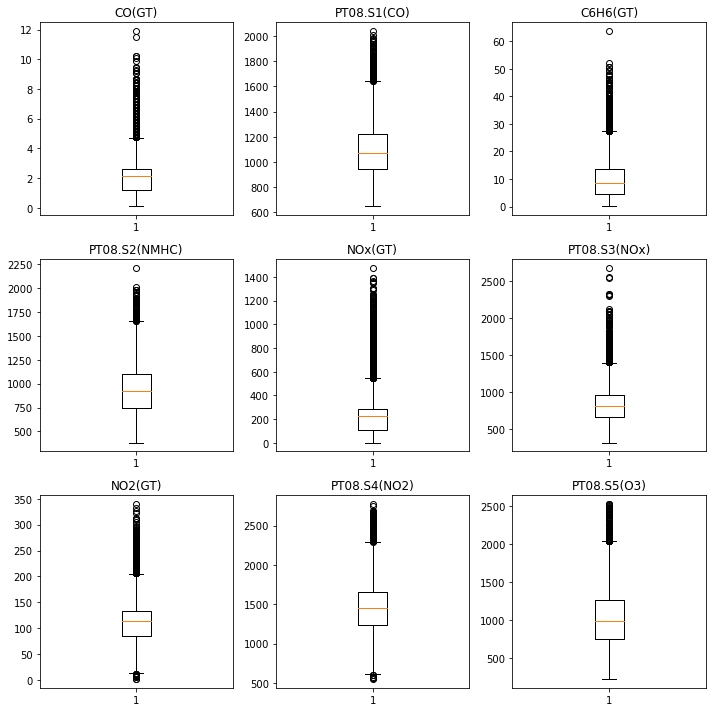

In [ ]:
# Membuat box plot
plt.figure(figsize=(10, 10))

# Kolom pertama
plt.subplot(3, 3, 1)
plt.boxplot(data['CO(GT)'])
plt.title('CO(GT)')

plt.subplot(3, 3, 2)
plt.boxplot(data['PT08.S1(CO)'])
plt.title('PT08.S1(CO)')

plt.subplot(3, 3, 3)
plt.boxplot(data['C6H6(GT)'])
plt.title('C6H6(GT)')

# Kolom kedua
plt.subplot(3, 3, 4)
plt.boxplot(data['PT08.S2(NMHC)'])
plt.title('PT08.S2(NMHC)')

plt.subplot(3, 3, 5)
plt.boxplot(data['NOx(GT)'])
plt.title('NOx(GT)')

plt.subplot(3, 3, 6)
plt.boxplot(data['PT08.S3(NOx)'])
plt.title('PT08.S3(NOx)')

# Kolom ketiga
plt.subplot(3, 3, 7)
plt.boxplot(data['NO2(GT)'])
plt.title('NO2(GT)')

plt.subplot(3, 3, 8)
plt.boxplot(data['PT08.S4(NO2)'])
plt.title('PT08.S4(NO2)')

plt.subplot(3, 3, 9)
plt.boxplot(data['PT08.S5(O3)'])
plt.title('PT08.S5(O3)')

plt.tight_layout()
plt.show()

In [ ]:
#transformasi data
q1 = data.quantile(0.25)
q3 = data.quantile(0.75)
IQR = q3-q1

In [ ]:
data=data[~((data<(q1-1.5*IQR)) |(data>(q3+1.5*IQR))).any(axis=1)]

In [ ]:
data

,CO(GT),PT08.S1(CO),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3)
0,2.6,1360.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0
1,2.0,1292.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0
2,2.2,1402.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0
3,2.2,1376.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0
4,1.6,1272.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0
...,...,...,...,...,...,...,...,...,...
9352,3.1,1314.0,13.5,1101.0,472.0,539.0,190.0,1374.0,1729.0
9353,2.4,1163.0,11.4,1027.0,353.0,604.0,179.0,1264.0,1269.0
9354,2.4,1142.0,12.4,1063.0,293.0,603.0,175.0,1241.0,1092.0
9355,2.1,1003.0,9.5,961.0,235.0,702.0,156.0,1041.0,770.0


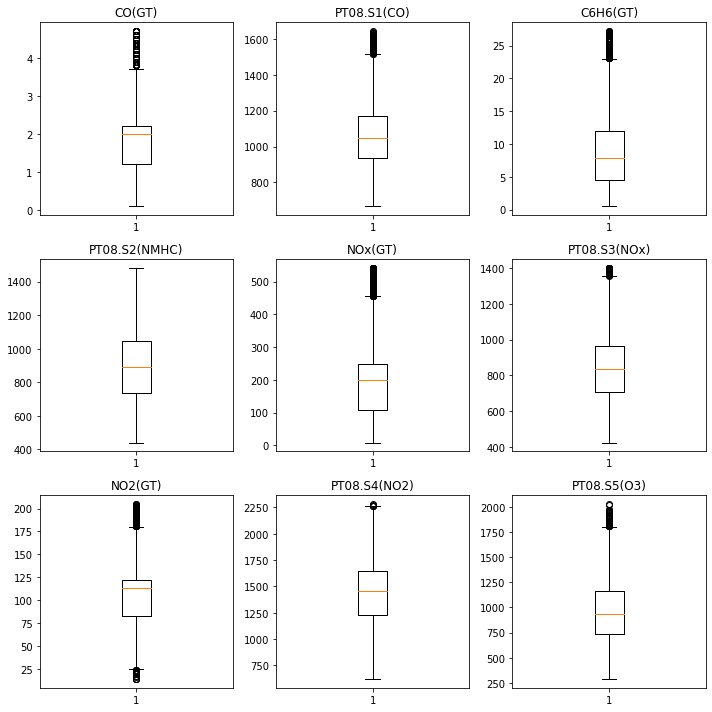

In [ ]:
# Membuat box plot
plt.figure(figsize=(10, 10))

# Kolom pertama
plt.subplot(3, 3, 1)
plt.boxplot(data['CO(GT)'])
plt.title('CO(GT)')

plt.subplot(3, 3, 2)
plt.boxplot(data['PT08.S1(CO)'])
plt.title('PT08.S1(CO)')

plt.subplot(3, 3, 3)
plt.boxplot(data['C6H6(GT)'])
plt.title('C6H6(GT)')

# Kolom kedua
plt.subplot(3, 3, 4)
plt.boxplot(data['PT08.S2(NMHC)'])
plt.title('PT08.S2(NMHC)')

plt.subplot(3, 3, 5)
plt.boxplot(data['NOx(GT)'])
plt.title('NOx(GT)')

plt.subplot(3, 3, 6)
plt.boxplot(data['PT08.S3(NOx)'])
plt.title('PT08.S3(NOx)')

# Kolom ketiga
plt.subplot(3, 3, 7)
plt.boxplot(data['NO2(GT)'])
plt.title('NO2(GT)')

plt.subplot(3, 3, 8)
plt.boxplot(data['PT08.S4(NO2)'])
plt.title('PT08.S4(NO2)')

plt.subplot(3, 3, 9)
plt.boxplot(data['PT08.S5(O3)'])
plt.title('PT08.S5(O3)')

plt.tight_layout()
plt.show()

In [ ]:
data.describe()

,CO(GT),PT08.S1(CO),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3)
count,7954.00000,7954.000000,7954.000000,7954.000000,7954.000000,7954.000000,7954.000000,7954.000000,7954.000000
mean,1.87623,1066.032704,8.780998,901.103030,199.850342,846.378287,106.067475,1433.024442,958.611697
std,0.89180,170.514074,5.397239,211.774845,113.446379,193.278709,34.322122,310.896129,307.048378
min,0.10000,667.000000,0.500000,440.000000,8.000000,425.000000,14.000000,621.000000,288.000000
25%,1.20000,937.000000,4.500000,736.000000,107.000000,706.000000,83.000000,1230.000000,732.000000
50%,2.00000,1050.000000,7.800000,891.000000,198.000000,834.000000,113.091251,1456.264598,937.000000
75%,2.20000,1169.000000,11.900000,1045.000000,246.896735,965.000000,122.000000,1642.000000,1160.000000
max,4.70000,1643.000000,27.200000,1484.000000,543.000000,1402.000000,205.000000,2283.000000,2028.000000


In [ ]:
#normalisasi data
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
data = scaler.fit_transform(data)

In [ ]:
(data)

array([[ 0.81163434,  1.72411444,  0.57792474, ...,  0.20199687,
         0.83304942,  1.00768405],
       [ 0.13879523,  1.32529531,  0.11469582, ..., -0.40989188,
         0.40522691,  0.04360598],
       [ 0.36307493,  1.97044391,  0.04057919, ...,  0.23113443,
         0.39236007,  0.37582207],
       ...,
       [ 0.58735464,  0.44554722,  0.67057053, ...,  2.00852556,
        -0.61768705,  0.43444844],
       [ 0.25093508, -0.369686  ,  0.13322498, ...,  1.45491193,
        -1.26102917, -0.61431217],
       [ 0.36307493,  0.02913313,  0.57792474, ...,  1.80456264,
        -0.97795864, -0.46448922]])

In [ ]:
data=pd.DataFrame(data,columns=['CO(GT)', 'PT08.S1(CO)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)',	'PT08.S4(NO2)', 'PT08.S5(O3)'])
data

,CO(GT),PT08.S1(CO),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3)
0,0.811634,1.724114,0.577925,0.684246,-0.298401,1.084625,0.201997,0.833049,1.007684
1,0.138795,1.325295,0.114696,0.254517,-0.853764,1.695181,-0.409892,0.405227,0.043606
2,0.363075,1.970444,0.040579,0.178961,-0.606936,1.519258,0.231134,0.392360,0.375822
3,0.363075,1.817954,0.077638,0.221461,-0.245509,1.270896,0.464235,0.485645,0.795978
4,-0.309764,1.207996,-0.422650,-0.307436,-0.606936,1.855581,0.289410,0.183274,0.493075
...,...,...,...,...,...,...,...,...,...
7949,1.372334,1.454325,0.874391,0.943972,2.399078,-1.590437,2.445589,-0.189865,2.509171
7950,0.587355,0.568712,0.485279,0.594522,1.350059,-1.254114,2.125076,-0.543703,1.010941
7951,0.587355,0.445547,0.670571,0.764525,0.821141,-1.259288,2.008526,-0.617687,0.434448
7952,0.250935,-0.369686,0.133225,0.282851,0.309854,-0.747042,1.454912,-1.261029,-0.614312


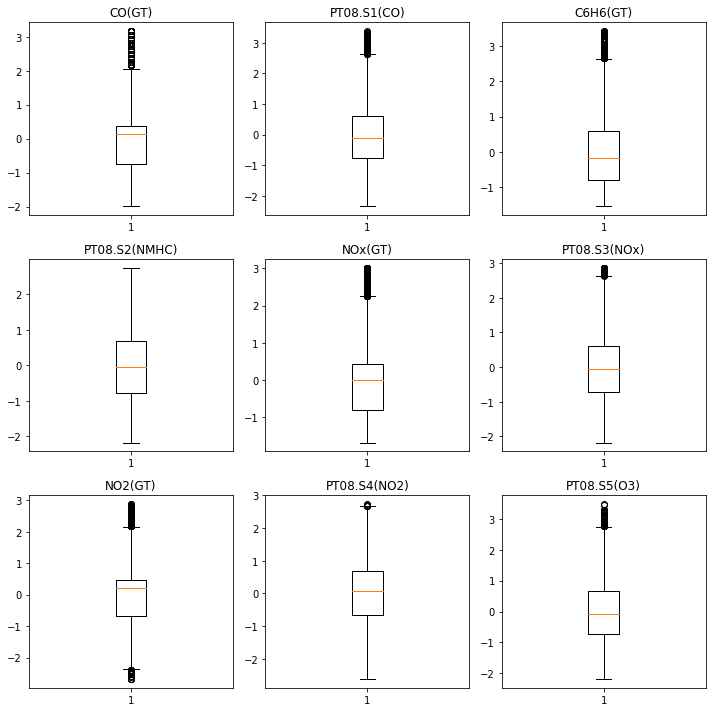

In [ ]:
# Membuat box plot
plt.figure(figsize=(10, 10))

# Kolom pertama
plt.subplot(3, 3, 1)
plt.boxplot(data['CO(GT)'])
plt.title('CO(GT)')

plt.subplot(3, 3, 2)
plt.boxplot(data['PT08.S1(CO)'])
plt.title('PT08.S1(CO)')

plt.subplot(3, 3, 3)
plt.boxplot(data['C6H6(GT)'])
plt.title('C6H6(GT)')

# Kolom kedua
plt.subplot(3, 3, 4)
plt.boxplot(data['PT08.S2(NMHC)'])
plt.title('PT08.S2(NMHC)')

plt.subplot(3, 3, 5)
plt.boxplot(data['NOx(GT)'])
plt.title('NOx(GT)')

plt.subplot(3, 3, 6)
plt.boxplot(data['PT08.S3(NOx)'])
plt.title('PT08.S3(NOx)')

# Kolom ketiga
plt.subplot(3, 3, 7)
plt.boxplot(data['NO2(GT)'])
plt.title('NO2(GT)')

plt.subplot(3, 3, 8)
plt.boxplot(data['PT08.S4(NO2)'])
plt.title('PT08.S4(NO2)')

plt.subplot(3, 3, 9)
plt.boxplot(data['PT08.S5(O3)'])
plt.title('PT08.S5(O3)')

plt.tight_layout()
plt.show()

# Clustering

### Kategori ISPU sebagaimana dimaksud pada ayat (3) terdiri atas:
* kategori baik;
* kategori sedang;
* kategori tidak sehat;
* kategori sangat tidak sehat;
* kategori berbahaya.

# K-Means

In [ ]:
from sklearn.cluster import KMeans

Elbow Method to determine the number of clusters to be formed:


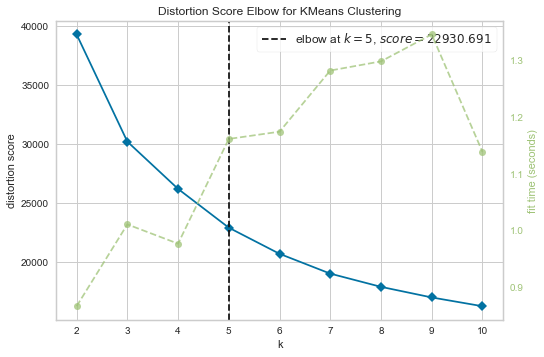

<AxesSubplot:title={'center':'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [ ]:
from yellowbrick.cluster import KElbowVisualizer
print('Elbow Method to determine the number of clusters to be formed:')
Elbow_M = KElbowVisualizer(KMeans(), k=10)
Elbow_M.fit(data)
Elbow_M.show()

In [ ]:
# inisialisasi model k-means dengan jumlah cluster yang telah di ditentukan
kmeans = KMeans(n_clusters=5)
label = kmeans.fit_predict(data)

In [ ]:
data['Cluster']=label
data

,CO(GT),PT08.S1(CO),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),Cluster
0,0.811634,1.724114,0.577925,0.684246,-0.298401,1.084625,0.201997,0.833049,1.007684,2
1,0.138795,1.325295,0.114696,0.254517,-0.853764,1.695181,-0.409892,0.405227,0.043606,2
2,0.363075,1.970444,0.040579,0.178961,-0.606936,1.519258,0.231134,0.392360,0.375822,2
3,0.363075,1.817954,0.077638,0.221461,-0.245509,1.270896,0.464235,0.485645,0.795978,2
4,-0.309764,1.207996,-0.422650,-0.307436,-0.606936,1.855581,0.289410,0.183274,0.493075,2
...,...,...,...,...,...,...,...,...,...,...
7949,1.372334,1.454325,0.874391,0.943972,2.399078,-1.590437,2.445589,-0.189865,2.509171,3
7950,0.587355,0.568712,0.485279,0.594522,1.350059,-1.254114,2.125076,-0.543703,1.010941,3
7951,0.587355,0.445547,0.670571,0.764525,0.821141,-1.259288,2.008526,-0.617687,0.434448,3
7952,0.250935,-0.369686,0.133225,0.282851,0.309854,-0.747042,1.454912,-1.261029,-0.614312,3


In [ ]:
data['Cluster'].value_counts()

2    2451
1    1655
4    1604
0    1283
3     961
Name: Cluster, dtype: int64

# Klasifikasi Model ANN

In [ ]:
# Library untuk visualisasi data
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler, LabelEncoder, OneHotEncoder, OrdinalEncoder

# ANN model
import keras
from keras.utils import np_utils
from tensorflow.keras import models
from tensorflow.keras import layers
from tensorflow.keras import optimizers
from tensorflow.keras.callbacks import EarlyStopping
from keras.wrappers.scikit_learn import KerasClassifier
from tensorflow import keras
from tensorflow.keras.utils import plot_model
from tensorflow.keras.models import Sequential
from keras import layers
from tensorflow.keras.layers import Dense, Activation, Dropout

# for checking testing results
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score, classification_report, confusion_matrix

## Train-Test Split

In [ ]:
X = data.drop(columns='Cluster')
y = data.Cluster

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=0)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((7158, 9), (796, 9), (7158,), (796,))

In [ ]:
y_test

779     2
244     4
7307    3
978     4
7427    1
       ..
2087    2
3526    4
4120    2
3251    2
6706    1
Name: Cluster, Length: 796, dtype: int32

## Model

In [ ]:
from keras.utils import np_utils
y_train = np_utils.to_categorical(y_train, num_classes = 5)
y_test = np_utils.to_categorical(y_test, num_classes = 5)

Dengan Hyperparameter tuning untuk mendapatkan parameter terbaik

In [ ]:
num_classes=5
model = Sequential()
def get_model_ann(units, activations, batch_size, learning_rate):
    model = Sequential()
    model.add(Dense(units=units,activation=activations, input_shape=(X_train.shape[1],)))
    model.add(Dense(units=units,activation=activations))
    model.add(Dense(units=units,activation=activations))
    model.add(Dense(num_classes,activation='softmax'))
    model.compile(loss ='categorical_crossentropy',optimizer=optimizers.Adam(learning_rate=learning_rate),metrics=['accuracy'])
    early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
    model.fit(X_train, y_train, epochs=100, batch_size=batch_size, validation_data=(X_test, y_test), callbacks=[early_stopping])
    return model

In [ ]:
from sklearn.model_selection import GridSearchCV
# Define the hyperparameters to search
param_grid = {
    'units':[16,32,64],
    'batch_size': [32,64,128],
    'learning_rate':[0.1,0.01, 0.001],
    'activations':['relu','sigmoid','tanh']
}

# Create the Keras model
model_ann = KerasClassifier(build_fn=get_model_ann)

# Perform grid search
grid = GridSearchCV(estimator=model_ann, param_grid=param_grid)
grid_result = grid.fit(X_train, y_train)

# Print the best hyperparameters and the corresponding model performance
print("Best: %f using %s" % (grid_result.best_score_, grid_result.best_params_))

Epoch 1/100
224/224 [==============================] - 3s 7ms/step - loss: 0.3612 - accuracy: 0.8826 - val_loss: 0.2174 - val_accuracy: 0.9296
Epoch 2/100
224/224 [==============================] - 1s 4ms/step - loss: 0.1991 - accuracy: 0.9352 - val_loss: 0.1177 - val_accuracy: 0.9523
Epoch 3/100
224/224 [==============================] - 1s 4ms/step - loss: 0.1945 - accuracy: 0.9413 - val_loss: 0.1857 - val_accuracy: 0.9322
Epoch 4/100
224/224 [==============================] - 1s 4ms/step - loss: 0.3401 - accuracy: 0.9019 - val_loss: 0.3430 - val_accuracy: 0.9234
Epoch 5/100
224/224 [==============================] - 1s 4ms/step - loss: 0.3483 - accuracy: 0.8935 - val_loss: 0.3080 - val_accuracy: 0.9146
Epoch 6/100
224/224 [==============================] - 1s 5ms/step - loss: 0.3031 - accuracy: 0.9089 - val_loss: 0.4453 - val_accuracy: 0.8719
Epoch 7/100
224/224 [==============================] - 1s 4ms/step - loss: 0.3579 - accuracy: 0.8857 - val_loss: 0.3012 - val_accuracy: 0.9384

In [ ]:
# melihat hasil parameter terbaik
print("Best: %f using %s" % (grid_result.best_score_, grid_result.best_params_))
mean = grid_result.cv_results_['mean_test_score']
std = grid_result.cv_results_['std_test_score']
params = grid_result.cv_results_['params']
for mean, stdev, param in zip(mean, std, params):
    print("%f (%f) with: %r" % (mean, stdev, param))

# mengambil model terbaik
best_model = grid_result.best_estimator_.model

Best: 0.996507 using {'activations': 'tanh', 'batch_size': 128, 'learning_rate': 0.001, 'units': 16}
0.639735 (0.199301) with: {'activations': 'relu', 'batch_size': 32, 'learning_rate': 0.1, 'units': 16}
0.556741 (0.127120) with: {'activations': 'relu', 'batch_size': 32, 'learning_rate': 0.1, 'units': 32}
0.536599 (0.130461) with: {'activations': 'relu', 'batch_size': 32, 'learning_rate': 0.1, 'units': 64}
0.976390 (0.009840) with: {'activations': 'relu', 'batch_size': 32, 'learning_rate': 0.01, 'units': 16}
0.983096 (0.003373) with: {'activations': 'relu', 'batch_size': 32, 'learning_rate': 0.01, 'units': 32}
0.980858 (0.010977) with: {'activations': 'relu', 'batch_size': 32, 'learning_rate': 0.01, 'units': 64}
0.993154 (0.001493) with: {'activations': 'relu', 'batch_size': 32, 'learning_rate': 0.001, 'units': 16}
0.989243 (0.003659) with: {'activations': 'relu', 'batch_size': 32, 'learning_rate': 0.001, 'units': 32}
0.988684 (0.002809) with: {'activations': 'relu', 'batch_size': 32, 

In [ ]:
model = Sequential()
model.add(Dense(units=16,activation='sigmoid', input_shape=(X_train.shape[1],)))
model.add(Dense(units=16,activation='sigmoid'))
model.add(Dense(units=16,activation='sigmoid'))
model.add(Dense(num_classes,activation='softmax'))
model.compile(loss ='categorical_crossentropy',optimizer=optimizers.Adam(learning_rate=0.001),metrics=['accuracy'])

model.summary()

Model: "sequential_407"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_1624 (Dense)          (None, 16)                160       
                                                                 
 dense_1625 (Dense)          (None, 16)                272       
                                                                 
 dense_1626 (Dense)          (None, 16)                272       
                                                                 
 dense_1627 (Dense)          (None, 5)                 85        
                                                                 
Total params: 789
Trainable params: 789
Non-trainable params: 0
_________________________________________________________________


## Training Model

In [ ]:
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history = model.fit(X_train, y_train, epochs=100, batch_size=32, validation_data=(X_test, y_test), callbacks=[early_stopping])

Epoch 1/100
224/224 [==============================] - 3s 7ms/step - loss: 1.5680 - accuracy: 0.2858 - val_loss: 1.4501 - val_accuracy: 0.3995
Epoch 2/100
224/224 [==============================] - 1s 4ms/step - loss: 1.2634 - accuracy: 0.4899 - val_loss: 1.0800 - val_accuracy: 0.5264
Epoch 3/100
224/224 [==============================] - 1s 4ms/step - loss: 1.0022 - accuracy: 0.5246 - val_loss: 0.9352 - val_accuracy: 0.5352
Epoch 4/100
224/224 [==============================] - 1s 4ms/step - loss: 0.8971 - accuracy: 0.6257 - val_loss: 0.8469 - val_accuracy: 0.6796
Epoch 5/100
224/224 [==============================] - 1s 3ms/step - loss: 0.8106 - accuracy: 0.6845 - val_loss: 0.7650 - val_accuracy: 0.6796
Epoch 6/100
224/224 [==============================] - 1s 3ms/step - loss: 0.7322 - accuracy: 0.6896 - val_loss: 0.6989 - val_accuracy: 0.6809
Epoch 7/100
224/224 [==============================] - 1s 3ms/step - loss: 0.6730 - accuracy: 0.7030 - val_loss: 0.6471 - val_accuracy: 0.7023

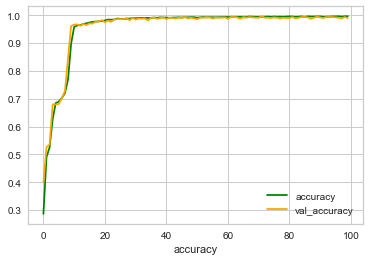

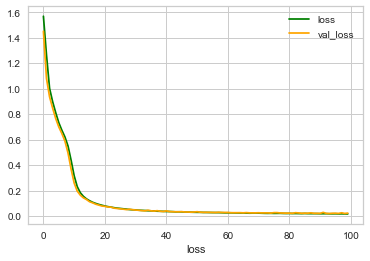

In [ ]:
import matplotlib.pyplot as plt
def plot_graphs(history, string):
    plt.plot(history.history[string], color = 'green')
    plt.plot(history.history['val_'+string], color = 'orange')
    plt.xlabel('epoch')
    plt.xlabel(string)
    plt.legend([string, "val_"+string])
    plt.show()

plot_graphs(history, 'accuracy')
plot_graphs(history, 'loss')

In [ ]:
evaluation = model.evaluate(X_test, y_test)

25/25 [==============================] - 1s 4ms/step - loss: 0.0225 - accuracy: 0.9899


In [ ]:
import numpy as np
ann_pred = np.argmax(model.predict(X_test),axis=1)
ann_pred

25/25 [==============================] - 2s 2ms/step


array([2, 4, 3, 4, 1, 4, 4, 2, 1, 2, 3, 4, 2, 0, 4, 2, 0, 0, 3, 2, 2, 4,
       4, 3, 4, 2, 2, 4, 1, 2, 2, 3, 1, 0, 4, 3, 2, 1, 3, 0, 3, 4, 4, 4,
       2, 2, 2, 4, 2, 1, 2, 4, 2, 1, 1, 0, 1, 1, 2, 1, 0, 1, 1, 1, 0, 4,
       4, 2, 0, 0, 3, 0, 4, 1, 2, 1, 2, 3, 4, 0, 1, 2, 0, 2, 2, 2, 3, 4,
       0, 1, 2, 3, 0, 3, 2, 0, 3, 2, 3, 0, 4, 2, 3, 2, 0, 4, 2, 2, 4, 4,
       3, 4, 2, 2, 2, 2, 1, 2, 4, 3, 0, 1, 2, 2, 2, 1, 1, 3, 2, 3, 3, 1,
       2, 2, 2, 1, 2, 2, 1, 1, 0, 3, 2, 1, 2, 1, 1, 4, 0, 2, 1, 2, 4, 3,
       0, 3, 1, 0, 4, 2, 1, 4, 1, 3, 4, 2, 2, 2, 4, 4, 2, 2, 1, 2, 2, 2,
       2, 2, 2, 4, 0, 1, 3, 1, 4, 1, 3, 1, 1, 1, 3, 2, 3, 3, 2, 0, 2, 0,
       1, 2, 1, 2, 1, 2, 4, 1, 1, 0, 1, 0, 3, 3, 1, 1, 1, 2, 4, 4, 3, 2,
       2, 3, 4, 1, 0, 2, 4, 1, 0, 3, 4, 4, 2, 2, 0, 2, 2, 2, 0, 2, 1, 1,
       0, 2, 0, 1, 3, 0, 0, 0, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 0, 1, 1, 4,
       4, 0, 4, 2, 4, 4, 2, 3, 4, 2, 2, 2, 2, 1, 2, 1, 2, 0, 2, 2, 2, 2,
       3, 1, 2, 2, 2, 1, 2, 2, 3, 2, 4, 4, 0, 2, 0,

In [ ]:
y_test = np.argmax(y_test,axis=1)
y_test

array([2, 4, 3, 4, 1, 4, 4, 2, 1, 2, 3, 4, 2, 0, 4, 2, 0, 0, 3, 2, 2, 4,
       4, 3, 4, 2, 2, 1, 1, 2, 2, 3, 1, 0, 4, 3, 2, 1, 3, 0, 3, 4, 4, 4,
       2, 2, 2, 4, 2, 1, 2, 4, 2, 1, 1, 0, 1, 1, 2, 1, 0, 1, 1, 1, 0, 4,
       4, 2, 0, 0, 3, 0, 4, 1, 2, 1, 2, 3, 4, 0, 1, 2, 0, 2, 2, 2, 3, 4,
       0, 1, 2, 3, 0, 3, 2, 0, 3, 2, 3, 0, 4, 2, 3, 2, 0, 4, 2, 2, 4, 4,
       3, 4, 2, 2, 2, 2, 1, 2, 4, 3, 0, 1, 2, 2, 2, 1, 1, 3, 2, 3, 3, 1,
       2, 2, 2, 1, 2, 2, 1, 1, 0, 3, 2, 1, 2, 1, 1, 4, 0, 2, 1, 2, 4, 3,
       0, 3, 1, 0, 4, 2, 1, 4, 1, 3, 4, 2, 2, 2, 4, 4, 2, 2, 1, 2, 2, 2,
       2, 2, 2, 4, 0, 1, 3, 1, 4, 1, 3, 1, 1, 1, 3, 2, 3, 3, 2, 0, 2, 0,
       1, 2, 1, 2, 1, 2, 4, 1, 1, 0, 1, 0, 3, 3, 1, 1, 1, 2, 4, 4, 3, 2,
       2, 3, 4, 1, 0, 2, 4, 1, 0, 3, 4, 4, 2, 2, 0, 2, 2, 2, 0, 2, 1, 1,
       0, 2, 0, 1, 3, 0, 0, 0, 1, 2, 2, 2, 2, 2, 2, 2, 2, 4, 0, 1, 1, 4,
       4, 0, 4, 2, 4, 4, 2, 3, 4, 2, 2, 2, 2, 1, 2, 1, 2, 0, 2, 2, 2, 2,
       3, 1, 2, 2, 2, 1, 2, 2, 3, 2, 4, 1, 0, 2, 0,

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score, classification_report, confusion_matrix
accuracy_score(ann_pred,y_test)

0.9899497487437185

In [ ]:
cm=confusion_matrix(ann_pred,y_test)

In [ ]:
cm

array([[118,   0,   0,   0,   0],
       [  0, 169,   0,   0,   0],
       [  0,   1, 261,   1,   2],
       [  0,   0,   0,  88,   0],
       [  0,   4,   0,   0, 152]], dtype=int64)

Text(0.5, 1.0, 'Confusion Matrix Model with ANN')

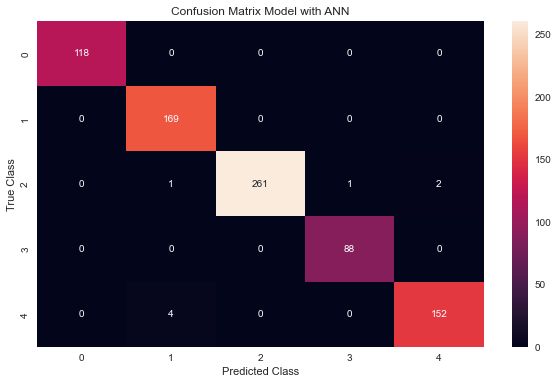

In [ ]:
fig = plt.figure(figsize = (10, 6))
sns.heatmap(cm, annot = True, fmt = "d")

# Labeling the X-axis
plt.xlabel("Predicted Class")

# Labeling the Y-axis
plt.ylabel("True Class")

# Give a title to the graph
plt.title("Confusion Matrix Model with ANN")